# Activation Functions in Neural Networks

In this notebook we will learn:

1. Why activation functions are needed
2. Linear vs Non-linear neural networks
3. Common activation functions
      - Step
      - Sigmoid
      - Tanh
      - ReLU
      - Leaky ReLU
      - Softmax
4. Vanishing Gradient Problem
5. Dying ReLU Problem
6. When to use which activation
7. Activation functions in Tensorflow



In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8")
plt.rcParams["figure.figsize"] = (7,4)

In [2]:
x = np.linspace(-10,10,200)

x[:10]

array([-10.        ,  -9.89949749,  -9.79899497,  -9.69849246,
        -9.59798995,  -9.49748744,  -9.39698492,  -9.29648241,
        -9.1959799 ,  -9.09547739])

To understand activation functions, we will visualize them.

We create values from -10 to 10 and observe how each
activation function transforms the input.


## Motivation: What Happens Without Activation?

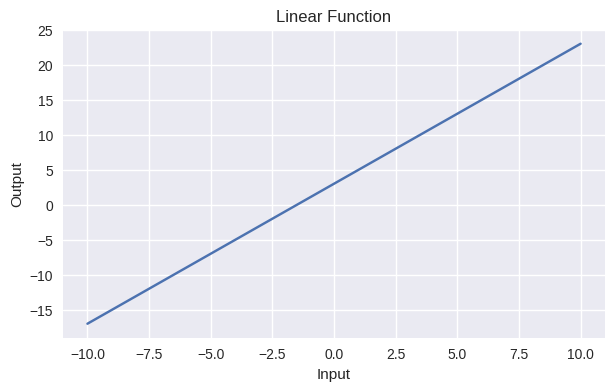

In [3]:
def linear(x):
    return 2*x + 3

y = linear(x)

plt.plot(x,y)
plt.title("Linear Function")
plt.xlabel("Input")
plt.ylabel("Output")
plt.show()


A neural network layer performs:

z = Wx + b

If we stack multiple layers without activation functions:

y = W2(W1x + b1) + b2

This simplifies to another linear function.

Therefore:

A deep network without activation functions behaves like
a single linear model.

This means it cannot learn complex patterns.


## Why Non-Linearity Matters

Activation functions introduce NON-LINEARITY.

This allows neural networks to learn complex decision
boundaries and approximate any continuous function
(Universal Approximation Theorem).


## Step Function (Historical)

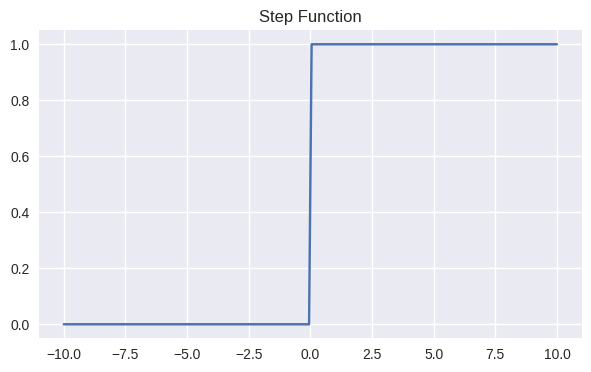

In [4]:
def step(x):
    return np.where(x >= 0,1,0)

plt.plot(x, step(x))
plt.title("Step Function")
plt.show()


### Step Activation Function (Perceptron)

The **Step Function** was used in early **Perceptrons (1950s)** developed by **Frank Rosenblatt**.  
It outputs either **0 or 1** depending on whether the input crosses a threshold.

$$
f(x) =
\begin{cases}
1 & \text{if } x \ge 0 \\
0 & \text{if } x < 0
\end{cases}
$$

### Problems

- **Not differentiable** at $x = 0$
- **Gradient = 0 almost everywhere**
- Because of this, it **cannot be trained using gradient descent**

This limitation led to the development of smoother activation functions like **Sigmoid, Tanh, and ReLU**.


## Sigmoid Function

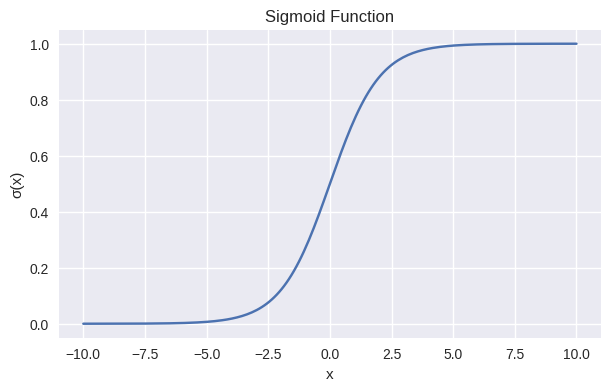

In [5]:
def sigmoid(x):
    return 1/(1+np.exp(-x))

plt.plot(x, sigmoid(x))
plt.title("Sigmoid Function")
plt.xlabel("x")
plt.ylabel("σ(x)")
plt.show()


### Sigmoid Interpretation

In [6]:
print("sigmoid(-10) =", sigmoid(-10))
print("sigmoid(0) =", sigmoid(0))
print("sigmoid(10) =", sigmoid(10))


sigmoid(-10) = 4.5397868702434395e-05
sigmoid(0) = 0.5
sigmoid(10) = 0.9999546021312976


### Sigmoid Function Analysis

The **Sigmoid function**, also known as the logistic function, is a non-linear activation function defined mathematically as:

$$\sigma(x) = \frac{1}{1 + e^{-x}}$$

#### Properties:
*   **Output Range:** It squashes any real-valued number into a range between 0 and 1, making it suitable for probabilities.
*   **Non-linear:** Its non-linear nature allows neural networks to learn complex relationships between inputs and outputs, which linear functions alone cannot.
*   **Monotonically Increasing:** As the input `x` increases, the output `σ(x)` also increases.
*   **Smooth Gradient:** It has a smooth, continuously differentiable gradient, which is beneficial for gradient-based optimization methods.

#### Use Cases:
*   **Binary Classification:** The output of the Sigmoid function can be interpreted as the probability of a given input belonging to a certain class (e.g., 0 or 1). For example, if the output is 0.8, it means there's an 80% chance of the input belonging to class 1.
*   **Output Layer of a Neural Network:** Often used in the output layer for binary classification problems.

#### Advantages:
*   **Probabilistic Interpretation:** The output directly provides a probability, which is intuitive and easy to interpret.
*   **Smooth Gradient:** Avoids abrupt changes and allows for continuous updates during backpropagation.

#### Disadvantages:
*   **Vanishing Gradient Problem:** As observed in the derivative plot, for very large positive or very large negative inputs, the gradient of the Sigmoid function becomes extremely small (close to zero). During backpropagation in deep neural networks, these small gradients are multiplied layer by layer, causing the gradients in earlier layers to 'vanish' or become practically zero. This severely slows down or even halts the learning process for the initial layers, making it difficult for the network to learn long-range dependencies.
*   **Not Zero-Centered Output:** The output of the Sigmoid function is always positive (between 0 and 1). This means that the gradients calculated during backpropagation will all be positive or all negative, leading to zigzagging updates for weights. This can make the optimization process less efficient and slower to converge.
*   **Computationally Expensive:** The exponential operation `e^(-x)` can be relatively more computationally intensive compared to simpler functions like ReLU.

### Sigmoid Derivative (Vanishing Gradient)

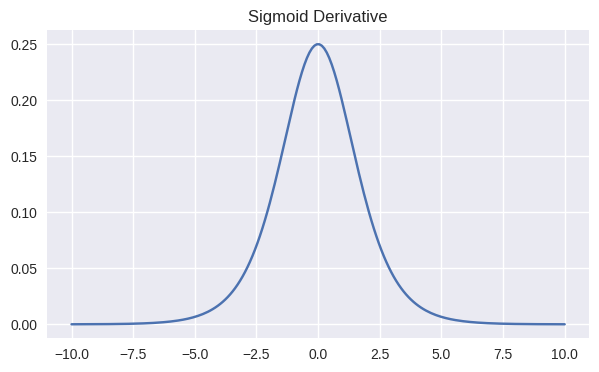

In [7]:
def sigmoid_derivative(x):
    s = sigmoid(x)
    return s*(1-s)

plt.plot(x, sigmoid_derivative(x))
plt.title("Sigmoid Derivative")
plt.show()


### Vanishing Gradient in Sigmoid

The **sigmoid function saturates at the extremes**.

When the input \(x\) becomes **very large positive** or **very large negative**, the sigmoid output approaches its limits:

- For large positive \(x\) → output ≈ **1**
- For large negative \(x\) → output ≈ **0**

In these regions, the **slope of the function becomes extremely small**.

$$
\sigma'(x) = \sigma(x)(1 - \sigma(x))
$$

When \(\sigma(x)\) is close to **0 or 1**, the derivative becomes **very close to 0**.

### Why This Is a Problem

During **backpropagation**, gradients are multiplied across layers.

If each layer produces a **very small gradient**, the signal shrinks as it moves backward through the network.

Eventually the gradient becomes **almost zero**, meaning:

- Earlier layers **receive almost no learning signal**
- Their weights **stop updating effectively**

This issue is called the **Vanishing Gradient Problem**, and it makes training **deep neural networks very difficult** when using sigmoid activations.


## Tanh Activation

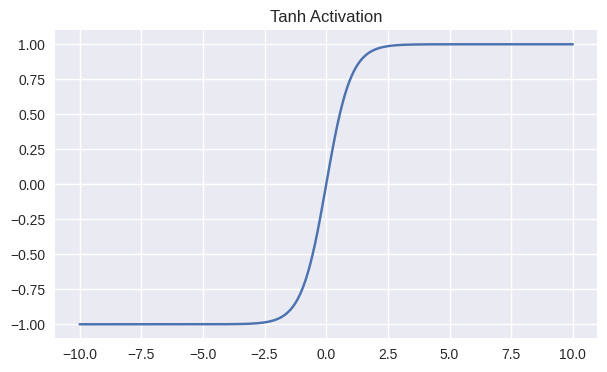

In [8]:
def tanh(x):
    return np.tanh(x)

plt.plot(x, tanh(x))
plt.title("Tanh Activation")
plt.show()


### Mathematical Definition and Properties of Tanh

The Tanh (Hyperbolic Tangent) function is defined mathematically as:

$$ \text{tanh}(x) = \frac{e^x - e^{-x}}{e^x + e^{-x}} $$

This can also be expressed in terms of the sigmoid function, as $\text{tanh}(x) = 2\sigma(2x) - 1$.

**Properties:**

*   **Output Range:** The output of the Tanh function ranges from -1 to 1. This means it is **zero-centered**, which is often advantageous during model training.
*   **Non-linearity:** Like Sigmoid, Tanh introduces non-linearity into the network, allowing it to learn complex patterns.

**Comparison to Sigmoid:**

Unlike the Sigmoid function, which outputs values between 0 and 1, the Tanh function outputs values between -1 and 1. This **zero-centered output** is a significant advantage. When the outputs of an activation function are all positive (like Sigmoid), the gradients flowing back through the network will always be either all positive or all negative. This can lead to a "zigzagging" effect in the weight updates, making training slower and less stable. With zero-centered outputs, the gradients are not restricted to one direction, which helps in faster convergence.

**Vanishing Gradient Problem:**

Despite its zero-centered nature, Tanh still suffers from the **vanishing gradient problem**, similar to the Sigmoid function. As seen in its derivative plot, the gradient values are very small (close to zero) for large positive or negative inputs. During backpropagation, these small gradients get multiplied across many layers, causing the gradients to shrink exponentially. This makes it difficult for the network to learn weights in earlier layers, as their updates become minuscule, effectively halting the learning process for those layers.

### Tanh Derivative

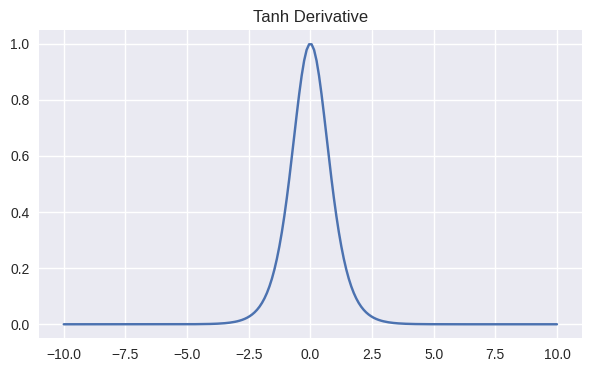

In [9]:
def tanh_derivative(x):
    return 1 - np.tanh(x)**2

plt.plot(x, tanh_derivative(x))
plt.title("Tanh Derivative")
plt.show()


### Vanishing Gradient in Tanh

Although **tanh performs better than sigmoid**, it still suffers from the **vanishing gradient problem**.

When the input \(x\) becomes **very large positive or very large negative**, the tanh function **saturates**:

- Large positive \(x\) → output ≈ **1**
- Large negative \(x\) → output ≈ **-1**

In these regions, the **slope of the function becomes very small**.

This means the **gradient approaches zero**.

### Why This Is a Problem

During **backpropagation**, gradients are multiplied across layers.

If the gradients are already **very small**, they shrink further as they move backward through the network.

As a result:

- Early layers receive **almost no learning signal**
- Weight updates become **extremely slow**

This is why deeper neural networks struggled when using **sigmoid or tanh activation functions**.


## ReLU (Rectified Linear Unit)

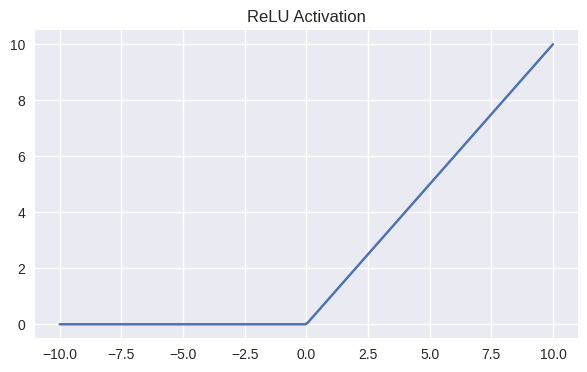

In [10]:
def relu(x):
    return np.maximum(0,x)

plt.plot(x, relu(x))
plt.title("ReLU Activation")
plt.show()


The Rectified Linear Unit (ReLU) function is defined as:

$f(x) = \max(0, x)$

This means that if the input $x$ is positive, the output is $x$, and if the input is zero or negative, the output is zero.

### Properties:
*   **Non-linear:** Despite its piecewise linear nature, ReLU is a non-linear function, allowing neural networks to learn complex relationships that linear models cannot.
*   **Simple:** It's very simple to compute, involving just a max operation.
*   **Sparsity:** For negative inputs, ReLU outputs zero, leading to sparse activation in the network, which can be computationally efficient and act as a form of regularization.

### Differences from Sigmoid and Tanh:
Unlike Sigmoid and Tanh, ReLU does not squash its output into a fixed range for positive inputs. This helps to prevent the vanishing gradient problem for positive values, as the derivative is 1 for $x > 0$.

### Detailed Advantages of ReLU:

*   **Computational Efficiency:** ReLU is computationally very inexpensive compared to activation functions like Sigmoid or Tanh. It only involves a simple comparison (`max(0, x)`), which makes it faster to compute during the forward and backward passes of a neural network.

*   **Mitigation of Vanishing Gradients (for positive inputs):** For positive inputs ($x > 0$), the derivative of ReLU is always 1. This constant derivative helps to combat the vanishing gradient problem, especially in deep neural networks, by allowing gradients to flow more effectively through the network. This contrasts sharply with Sigmoid and Tanh, whose derivatives become very small for large positive or negative inputs.

*   **Sparse Activation:** When the input to a ReLU neuron is negative, the output is 0. This leads to a phenomenon called 'sparse activation', where a significant number of neurons in the network might output 0. This sparsity can be beneficial for several reasons:
    *   It can lead to more efficient computations, as operations involving zero can sometimes be skipped.
    *   It can act as a form of implicit regularization, making the network learn more robust features and potentially reducing overfitting.

### ReLU Derivative

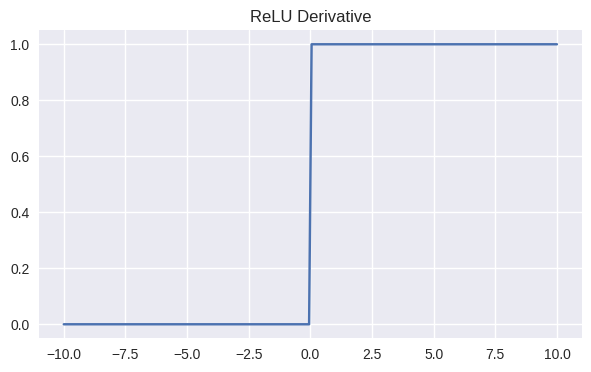

In [11]:
def relu_derivative(x):
    return np.where(x>0,1,0)

plt.plot(x, relu_derivative(x))
plt.title("ReLU Derivative")
plt.show()


### The 'Dying ReLU' Problem:

The 'Dying ReLU' problem occurs when a ReLU neuron exclusively outputs zero for all inputs and consequently stops learning. This happens when the weighted sum of inputs to a ReLU neuron is always negative during training.

#### Why it occurs:
1.  **Negative Inputs:** If a neuron's input (after applying weights and bias) consistently remains negative, the ReLU function will always output 0.
2.  **Zero Gradient:** Since the derivative of ReLU for negative inputs is 0, during backpropagation, the gradient flowing through this neuron will also be 0. This means the neuron's weights will not be updated.
3.  **Irreversible State:** Once a neuron 'dies' in this manner, it's very difficult for it to recover because its weights are no longer being adjusted. It's effectively removed from the network's active learning process.

#### Consequences:
*   **Reduced Model Capacity:** A significant number of 'dead' neurons reduce the effective size and learning capacity of the neural network.
*   **Poor Performance:** The network may fail to learn complex patterns or generalize well to new data, leading to suboptimal performance.
*   **Instability:** Can contribute to training instability.

## Leaky ReLU

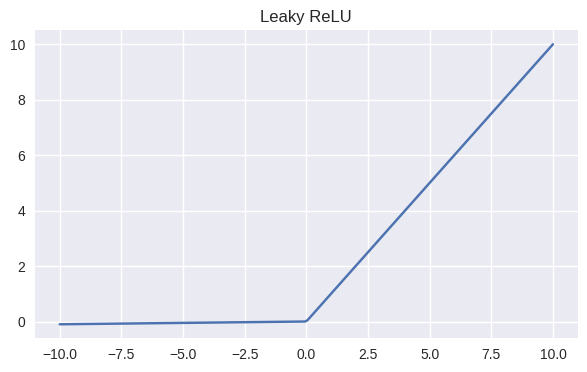

In [12]:
def leaky_relu(x, alpha=0.01):
    return np.where(x>0,x,alpha*x)

plt.plot(x, leaky_relu(x))
plt.title("Leaky ReLU")
plt.show()


### Leaky ReLU as a Solution to Dying ReLU:

The Leaky ReLU function is designed to address the 'Dying ReLU' problem. It is defined as:

$f(x) = x \quad \text{if } x > 0$
$f(x) = \alpha x \quad \text{if } x \le 0$

Where $\alpha$ (alpha) is a small positive constant, typically around 0.01.

#### How it solves the 'Dying ReLU' problem:
*   **Non-zero Gradient for Negative Inputs:** Unlike standard ReLU, Leaky ReLU allows a small, non-zero gradient for negative inputs. Because $\alpha$ is a positive constant, $f(x) = \alpha x$ for $x \le 0$ means the derivative is $\alpha$ (e.g., 0.01) instead of 0. This ensures that neurons are still able to learn, even if their activation is negative.
*   **Prevents Stagnation:** By allowing a small flow of gradient for negative inputs, Leaky ReLU prevents the neuron from becoming completely inactive or 'dead'. The weights can still be adjusted during backpropagation, enabling the neuron to potentially recover and participate in learning.
*   **Maintains Advantages:** It retains most of the advantages of ReLU, such as computational efficiency and the ability to mitigate vanishing gradients for positive inputs.

## Compare Activations

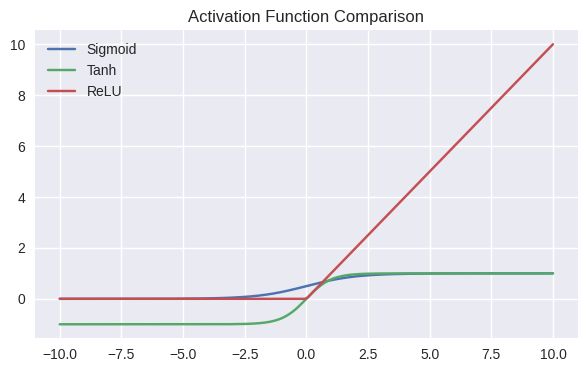

In [13]:
plt.plot(x, sigmoid(x), label="Sigmoid")
plt.plot(x, tanh(x), label="Tanh")
plt.plot(x, relu(x), label="ReLU")

plt.legend()
plt.title("Activation Function Comparison")
plt.show()


## Comparison of Activation Functions

| Feature           | Sigmoid                                  | Tanh                                     | ReLU (Rectified Linear Unit)                       |
|:------------------|:-----------------------------------------|:-----------------------------------------|:---------------------------------------------------|
| **Output Range**  | (0, 1)                                   | (-1, 1)                                  | [0, +infinity)                                     |
| **Zero-Centered** | No (output is always positive)           | Yes                                      | No (output is always non-negative)                 |
| **Vanishing Gradient** | High (for extreme values of input)    | High (for extreme values of input)       | Less prone (gradient is 1 for positive inputs)     |
| **Computational Cost** | High (due to `exp` function)           | High (due to `exp` function)           | Low (simple `max` operation)                       |
| **Dying ReLU Problem** | Not applicable                         | Not applicable                           | Yes (neurons can become inactive for negative inputs) |
| **Use Cases**     | Binary classification (output as probability) | Hidden layers (often preferred over sigmoid) | Hidden layers (most common choice for deep learning) |

### Key Takeaways:

*   **Sigmoid**: Historically significant, but rarely used in hidden layers of deep networks due to vanishing gradients and non-zero-centered output. Good for output layers in binary classification.
*   **Tanh**: Addresses the non-zero-centered issue of sigmoid, making it often a better choice for hidden layers than sigmoid. Still suffers from vanishing gradients.
*   **ReLU**: The most popular activation function for deep neural networks due to its computational efficiency and ability to mitigate the vanishing gradient problem. However, it can suffer from the "Dying ReLU" problem where neurons can become permanently inactive if their input is always negative.
*   **Leaky ReLU** (and its variants like PReLU, ELU): Designed to address the Dying ReLU problem by allowing a small, non-zero gradient for negative inputs. These are often used as alternatives to standard ReLU to improve robustness.

## Softmax (Multiclass)

The Softmax function is an activation function often used in the output layer of a neural network for multi-class classification problems. It takes a vector of arbitrary real values (often called logits or scores) and squashes them into a vector of values between 0 and 1 that sum to 1.

### Mathematical Definition:
$$ \text{Softmax}(x_i) = \frac{e^{x_i}}{\sum_{j=1}^{K} e^{x_j}} $$
Where:
*   $x_i$ is the $i$-th element of the input vector (logit or score for class $i$).
*   $K$ is the number of classes.
*   $e^{x_i}$ is the exponential of the input value for class $i$.
*   $\sum_{j=1}^{K} e^{x_j}$ is the sum of the exponentials of all input values.

### Primary Use Case:
Its primary use case is in the output layer of a neural network for multi-class classification. It converts the raw, unnormalized scores (logits) from the previous layer into a probability distribution over the predicted classes. Each output value can be interpreted as the probability that the input belongs to a particular class, with all probabilities summing up to 1. This makes it suitable for problems where an input can only belong to one category among several.

In [14]:
def softmax(x):
    exp_x = np.exp(x - np.max(x))
    return exp_x/exp_x.sum()


In [15]:
scores = np.array([2.0,1.0,0.1])

softmax(scores)

array([0.65900114, 0.24243297, 0.09856589])

#### Interpretation of Softmax Output:

The output array `[0.65900114, 0.24243297, 0.09856589]` represents a probability distribution over three classes for the given input scores `[2.0, 1.0, 0.1]`.

*   The first value, `0.659`, indicates a 65.9% probability that the input belongs to the first class.
*   The second value, `0.242`, indicates a 24.2% probability that the input belongs to the second class.
*   The third value, `0.098`, indicates a 9.8% probability that the input belongs to the third class.

Notice that these probabilities sum up to approximately 1 (0.65900114 + 0.24243297 + 0.09856589 ≈ 1.0), which is a key characteristic of the Softmax function, making its output easily interpretable for multi-class classification tasks.

## Implement Activation Functions with TensorFlow

In [19]:
import tensorflow as tf

# 2. Create a simple Sequential Keras model.
model = tf.keras.Sequential([
    # 3. Add a Dense layer to the model and apply the sigmoid activation function.
    tf.keras.layers.Dense(units=10, activation='sigmoid', input_shape=(5,)),
    # 4. Add another Dense layer with the tanh activation function.
    tf.keras.layers.Dense(units=10, activation='tanh'),
    # 5. Add a third Dense layer with the relu activation function.
    tf.keras.layers.Dense(units=10, activation='relu'),
    # 6. Add an output Dense layer with a softmax activation function.
    tf.keras.layers.Dense(units=3, activation='softmax') # 3 units for 3 classes
])

# 7. Print a summary of the model.
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 10)             │            60 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 3)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 313 (1.22 KB)

 Trainable params: 313 (1.22 KB)

 Non-trainable params: 0 (0.00 B)

In [20]:
import tensorflow as tf

# 2. Create a simple Sequential Keras model.
model = tf.keras.Sequential([
    # Define the input layer explicitly
    tf.keras.Input(shape=(5,)),
    # 3. Add a Dense layer to the model and apply the sigmoid activation function.
    tf.keras.layers.Dense(units=10, activation='sigmoid'),
    # 4. Add another Dense layer with the tanh activation function.
    tf.keras.layers.Dense(units=10, activation='tanh'),
    # 5. Add a third Dense layer with the relu activation function.
    tf.keras.layers.Dense(units=10, activation='relu'),
    # 6. Add an output Dense layer with a softmax activation function.
    tf.keras.layers.Dense(units=3, activation='softmax') # 3 units for 3 classes
])

# 7. Print a summary of the model.
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                │ (None, 10)             │            60 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 3)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 313 (1.22 KB)

 Trainable params: 313 (1.22 KB)

 Non-trainable params: 0 (0.00 B)

## Summary of Key Learnings and Best Practices

Choosing the right activation function is crucial for the performance and training stability of a neural network. Here's a summary of when to use which function and general best practices:

### When to Use Which Activation Function:

*   **Sigmoid**: Primarily for **binary classification problems in the output layer**, where you need to output a probability between 0 and 1. Rarely used in hidden layers due to vanishing gradients and non-zero-centered output, which slows down training.
*   **Tanh**: Generally preferred over Sigmoid for **hidden layers** when Sigmoid-like behavior is desired, as its output is zero-centered (-1 to 1), which aids in faster convergence. Still susceptible to the vanishing gradient problem.
*   **ReLU (Rectified Linear Unit)**: The most common choice for **hidden layers** in deep neural networks. Its advantages include computational efficiency and effective mitigation of the vanishing gradient problem for positive inputs. However, be aware of the 'Dying ReLU' problem.
*   **Leaky ReLU (and variants like PReLU, ELU)**: A good alternative to standard ReLU for **hidden layers**, especially when facing the 'Dying ReLU' problem. It ensures a small, non-zero gradient for negative inputs, allowing neurons to continue learning.
*   **Softmax**: Exclusively used in the **output layer for multi-class classification problems**. It converts a vector of raw scores into a probability distribution, where each output represents the probability of belonging to a specific class, and all probabilities sum to 1.

### General Guidelines and Considerations:

1.  **Non-linearity is Key**: Activation functions introduce non-linearity, enabling neural networks to learn complex patterns that linear models cannot. Without them, stacking layers would only result in a single linear transformation.
2.  **Vanishing/Exploding Gradients**: Be mindful of these issues. Sigmoid and Tanh are prone to vanishing gradients in deep networks. ReLU-based functions generally alleviate this for positive inputs.
3.  **Computational Cost**: Simple functions like ReLU are computationally cheaper than Sigmoid or Tanh, which involve exponential calculations.
4.  **Zero-Centered Output**: Activation functions with zero-centered outputs (like Tanh) can lead to faster convergence during training by preventing zigzagging updates.
5.  **The 'Dying ReLU' Problem**: If using ReLU, be aware that neurons can become inactive if their inputs are consistently negative. Leaky ReLU and its variants are designed to address this.

### Best Practices for Activation Function Selection:

*   **Hidden Layers**: Start with **ReLU** as the default choice. If you encounter the 'Dying ReLU' problem or need more robust performance, consider **Leaky ReLU**, PReLU, or ELU. Tanh can also be used, but is less common than ReLU variants in very deep networks.
*   **Output Layers**:
    *   **Binary Classification**: Use **Sigmoid** (or no activation with `from_logits=True` in `tf.keras.losses.BinaryCrossentropy`).
    *   **Multi-class Classification**: Use **Softmax** (or no activation with `from_logits=True` in `tf.keras.losses.CategoricalCrossentropy` or `SparseCategoricalCrossentropy`).
    *   **Regression**: Typically, **no activation function (linear activation)** is used, as the output needs to be a continuous value without bounds.

### Importance of Experimentation:

Ultimately, the best activation function for a specific problem and network architecture often comes down to **experimentation**. Start with general recommendations, but be prepared to test different activation functions and their variants to find what works best for your particular task and dataset.

## Summary:

### Data Analysis Key Findings

*   **Necessity of Non-linearity**: Activation functions are crucial for neural networks to learn complex, non-linear patterns, preventing them from collapsing into simple linear models, which would severely limit their predictive power.
*   **Sigmoid Function**:
    *   Defined as $\sigma(x) = \frac{1}{1 + e^{-x}}$, it squashes outputs to the range (0, 1).
    *   Primarily used in the output layer for binary classification to provide probabilistic interpretation.
    *   Major drawbacks include susceptibility to the vanishing gradient problem for extreme input values, non-zero-centered output, and higher computational cost due to exponential operations.
*   **Tanh (Hyperbolic Tangent) Function**:
    *   Defined as $\text{tanh}(x) = \frac{e^x - e^{-x}}{e^x + e^{-x}}$, with an output range of (-1, 1).
    *   Offers an advantage over Sigmoid due to its zero-centered output, which can lead to faster convergence by preventing zigzagging weight updates during training.
    *   Still suffers from the vanishing gradient problem, similar to Sigmoid, for large positive or negative inputs.
*   **ReLU (Rectified Linear Unit) Function**:
    *   Defined as $f(x) = \max(0, x)$.
    *   Highly favored in hidden layers of deep neural networks due to its computational efficiency (simple `max` operation) and its effectiveness in mitigating the vanishing gradient problem for positive inputs (where the derivative is 1).
    *   Its main disadvantage is the 'Dying ReLU' problem, where neurons can become permanently inactive if their inputs are consistently negative, leading to zero gradients and halting learning.
*   **Leaky ReLU Function**:
    *   A variant of ReLU, defined as $f(x) = x$ for $x > 0$ and $f(x) = \alpha x$ for $x \le 0$ (where $\alpha$ is a small positive constant, e.g., 0.01).
    *   Designed to address the 'Dying ReLU' problem by allowing a small, non-zero gradient for negative inputs, enabling neurons to continue learning even when their activation is negative.
*   **Softmax Function**:
    *   Mathematically defined as $\text{Softmax}(x_i) = \frac{e^{x_i}}{\sum_{j=1}^{K} e^{x_j}}$.
    *   Exclusively used in the output layer for multi-class classification, converting raw scores (logits) into a probability distribution over multiple classes, with all probabilities summing to 1.
*   **Comparative Analysis**: A comprehensive comparison highlights that ReLU and its variants are generally preferred for hidden layers due to efficiency and gradient flow, while Sigmoid is reserved for binary classification outputs and Softmax for multi-class outputs.
*   **TensorFlow/Keras Implementation**: Demonstrated seamless integration of these activation functions within `tf.keras.Sequential` models using the `activation` argument in `Dense` layers.

### Insights or Next Steps

*   The selection of activation functions is not a one-size-fits-all problem; it depends on the specific layer (hidden vs. output) and the nature of the task (binary classification, multi-class classification, regression).
*   While ReLU is a strong default for hidden layers, it's crucial to be aware of the 'Dying ReLU' problem and consider alternatives like Leaky ReLU, PReLU, or ELU if training issues arise. Experimentation remains key to finding the optimal activation function for a given neural network architecture and dataset.
